# Week 2 — Buner Crop Health Project
**Plan ke hisab se, koi shortcut nahi.**

Week 1 ho gaya: weather data (Open-Meteo) + pehli NDVI map (Sentinel-2).

Week 2 ke 4 steps:
1. CSV load + check — `buner_monthly_merged.csv` (36 mahine)
2. API se asal satellite bands (Red B04 + NIR B08) la kar **khud NDVI calculate** karna — April 2025
3. Apna NDVI, CSV wale NDVI se cross-check — April 2025 ka CSV `ndvi_veg = 0.298`
4. Graph — 36 mahine ka NDVI vs barish, aur dono data ka alignment samajhna

**Rule: ek step ek dafa. Har step ke baad screenshot bhejna hai, phir agla step.**


## STEP 1 — CSV load + check
Pehle Colab ke left side **Files** me ja kar **Upload** se ye file upload karo:
`buner_monthly_merged.csv` (ye Week 1 wale ZIP ke andar thi)

Phir neeche wala cell chalao (Run button / Shift+Enter).


In [5]:
import pandas as pd
import zipfile
import os

# Extract the ZIP file containing the dataset if the CSV is missing
if not os.path.exists('buner_monthly_merged.csv') and os.path.exists('/content/buner-crop-health-data.zip'):
    with zipfile.ZipFile('/content/buner-crop-health-data.zip', 'r') as zip_ref:
        zip_ref.extractall('.')

df = pd.read_csv('buner_monthly_merged.csv')
print('Shape:', df.shape)          # (36, 12) ana chahiye — 36 mahine, 12 columns
print('Khali (missing) values:', int(df.isna().sum().sum()))  # 0 ana chahiye
df.head()

Shape: (36, 12)
Khali (missing) values: 0


,month,tmax,tmin,tmean,precip_mm,et0_mm,date,cloud,clear_pct,ndvi_land,ndvi_veg,veg_share
0,2023-01,12.99,2.43,7.34,89.1,45.25,2023-01-03,0.0,82,0.306,0.322,73.7
1,2023-02,18.25,5.95,11.72,82.1,67.82,2023-02-07,0.0,90,0.331,0.359,78.3
2,2023-03,21.39,9.82,15.50,45.4,97.52,2023-03-09,0.0,87,0.345,0.372,76.7
3,2023-04,24.78,12.90,18.84,120.0,129.13,2023-04-08,0.0,97,0.349,0.368,89.2
4,2023-05,27.70,16.35,22.16,151.2,150.28,2023-05-10,0.1,98,0.322,0.341,88.0


✅ Step 1 pass agar: Shape **(36, 12)** aur missing values **0** ayen.
**Is ka screenshot bhejo — phir Step 2 chalenge.**


## STEP 2 — API se asal bands la kar khud NDVI calculate karna (April 2025)
Satellite source wahi jo plan me alternative tha: **Sentinel-2 via Microsoft Planetary Computer** (free, koi sign-in nahi).
Pehle ye install cell chalao:


In [6]:
!pip install -q planetary-computer pystac rasterio


In [7]:
# April 2025 ke liye sab se saaf (kam badal wali) Sentinel-2 photo dhoondna — API search
import json, subprocess

BBOX = [72.40, 34.33, 72.54, 34.45]   # Buner — Daggar-Jowar valley (Week 1 wala ilaqa)
body = {'collections': ['sentinel-2-l2a'], 'bbox': BBOX,
        'datetime': '2025-04-01T00:00:00Z/2025-04-30T23:59:59Z', 'limit': 40}
raw = subprocess.run(['curl', '-s', '-X', 'POST',
                      'https://planetarycomputer.microsoft.com/api/stac/v1/search',
                      '-H', 'Content-Type: application/json', '-d', json.dumps(body)],
                     capture_output=True, text=True).stdout
feats = json.loads(raw)['features']
feats = sorted(feats, key=lambda f: f['properties'].get('eo:cloud_cover', 100))
print('Photos mili:', len(feats))
print('Sab se saaf photo ki date:', feats[0]['properties']['datetime'][:10],
      '| badal %:', feats[0]['properties']['eo:cloud_cover'])


Photos mili: 15
Sab se saaf photo ki date: 2025-04-29 | badal %: 0.000926


In [8]:
# Us photo ke Red (B04), NIR (B08) aur SCL bands parh kar NDVI calculate karna
import numpy as np, rasterio, planetary_computer, pystac
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds
import os
os.environ['GDAL_HTTP_UNSAFESSL'] = 'YES'

item = planetary_computer.sign(pystac.Item.from_dict(feats[0]))

def read(asset):
    with rasterio.open(item.assets[asset].href) as src:
        b = transform_bounds('EPSG:4326', src.crs, *BBOX)
        win = from_bounds(*b, transform=src.transform).intersection(Window(0, 0, src.width, src.height))
        return src.read(1, window=win, out_shape=(220, 220)).astype('float32')

red, nir, scl = read('B04'), read('B08'), read('SCL')
ndvi = (nir - red) / (nir + red + 1e-9)          # <-- NDVI formula, yehi Week 2 ka asal kaam hai
clear = np.isin(scl, [4, 5])                     # badal ke baghair wali zameen
veg = clear & (ndvi > 0.2)                       # hariyali wala hissa
print('NDVI (sari saaf zameen):', round(float(ndvi[clear].mean()), 3))
print('NDVI (sirf hariyali):  ', round(float(ndvi[veg].mean()), 3))
print('Hariyali ka hissa %:   ', round(float(veg.mean() * 100), 1))


NDVI (sari saaf zameen): 0.274
NDVI (sirf hariyali):   0.298
Hariyali ka hissa %:    81.2


## STEP 3 — Cross-check
Upar wale numbers ko CSV se milao:
- Tumhara **NDVI (sirf hariyali)** ≈ **0.298** ana chahiye
- **Hariyali ka hissa** ≈ **81.2%** ana chahiye

Agar ye mile to is ka matlab hai: tum ne khud wahi NDVI banaya jo Week 1 ki CSV me tha. ✅


In [9]:
# CSV se April 2025 ki row nikal kar muqabla
print(df[df['month'] == '2025-04'][['month', 'date', 'ndvi_land', 'ndvi_veg', 'veg_share']])


      month        date  ndvi_land  ndvi_veg  veg_share
27  2025-04  2025-04-29      0.274     0.298       81.2


## STEP 4 — Graph: NDVI vs Barish (36 mahine)
Dono data pehle se aik hi file me mahine ke hisab se aligned hain (Week 1 ZIP).
Ye graph chalao aur dekho: barish zyada → NDVI zyada (kuch mahine baad asar ata hai).


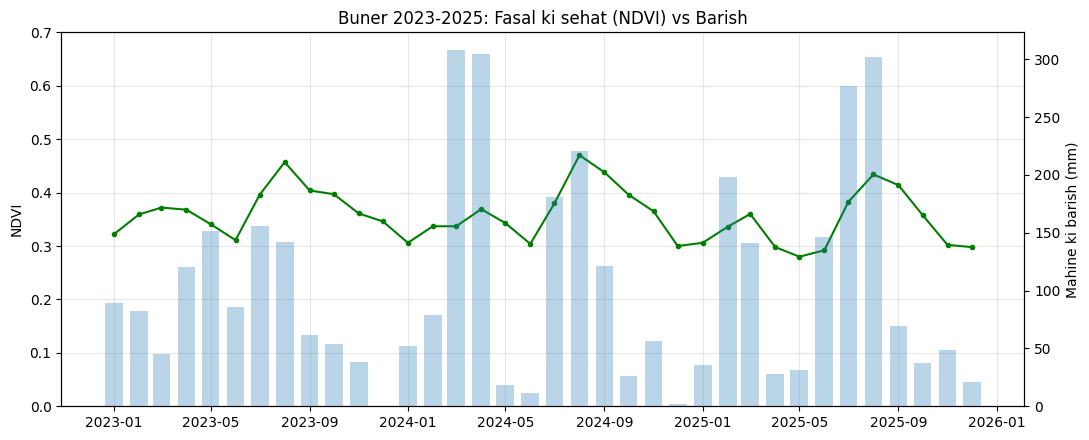

Sab se sehatmand mahina: 2024-08 0.47
Sab se kamzor mahina:   2025-05 0.28


In [10]:
import matplotlib.pyplot as plt

x = pd.to_datetime(df['month'])
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(x, df['ndvi_veg'], 'g-o', ms=3, label='NDVI (fasal ki sehat)')
ax1.set_ylabel('NDVI'); ax1.set_ylim(0, 0.7); ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
ax2.bar(x, df['precip_mm'], width=22, alpha=0.3, label='Barish (mm)')
ax2.set_ylabel('Mahine ki barish (mm)')
plt.title('Buner 2023-2025: Fasal ki sehat (NDVI) vs Barish')
fig.tight_layout(); plt.show()
print('Sab se sehatmand mahina:', df.loc[df['ndvi_veg'].idxmax(), 'month'], round(df['ndvi_veg'].max(), 3))
print('Sab se kamzor mahina:  ', df.loc[df['ndvi_veg'].idxmin(), 'month'], round(df['ndvi_veg'].min(), 3))


🎉 **Week 2 khatam** jab: Step 1 ka check pass, Step 2 ka apna NDVI ≈ 0.298, aur graph ban jaye.
Phir **Week 3**: Random Forest model — agle mahine ki fasal ki kamzori (stress) ki peshangoi.


# Week 3 — Random Forest: Fasal ke Stress ki Peshangoi (Buner)
**Week 2 ho gaya** ✅ — tum ne khud API se NDVI calculate kiya (0.298, CSV se exact match) aur graph bhi banaya.

Week 3 ka kaam: **machine learning model** jo is mahine ke data se bataye ke **agle mahine fasal par stress (kamzori) ayega ya nahi.**

Steps:
1. Data load + **target banana** — stress ki tareef: agle mahine NDVI **0.03 ya zyada gir jaye** to stress = 1, warna 0
2. Model train — **Random Forest**, waqt ke hisab se train/test taqseem (purane mahine train, naye mahine test)
3. Result check — accuracy
4. Sab se ahem wajahen (feature importance) + **akhri mahine ki live prediction**

**Rule wahi: ek step ek dafa, har step ke baad screenshot.**


## STEP 1 — Data load + target banana
Pehle Week 1 ki CSV file is notebook me bhi upload karo (Files > Upload): `buner_monthly_merged.csv`
— ya pura `buner-crop-health-data.zip` upload kar do, code khud extract kar lega.


In [11]:
import pandas as pd, os, zipfile

# Agar CSV mojood nahi aur ZIP hai to pehle extract karo
if not os.path.exists('buner_monthly_merged.csv') and os.path.exists('buner-crop-health-data.zip'):
    with zipfile.ZipFile('buner-crop-health-data.zip') as z:
        z.extractall('.')

df = pd.read_csv('buner_monthly_merged.csv')
print('Shape:', df.shape)   # (36, 12) ana chahiye
df.head()


Shape: (36, 12)


,month,tmax,tmin,tmean,precip_mm,et0_mm,date,cloud,clear_pct,ndvi_land,ndvi_veg,veg_share
0,2023-01,12.99,2.43,7.34,89.1,45.25,2023-01-03,0.0,82,0.306,0.322,73.7
1,2023-02,18.25,5.95,11.72,82.1,67.82,2023-02-07,0.0,90,0.331,0.359,78.3
2,2023-03,21.39,9.82,15.50,45.4,97.52,2023-03-09,0.0,87,0.345,0.372,76.7
3,2023-04,24.78,12.90,18.84,120.0,129.13,2023-04-08,0.0,97,0.349,0.368,89.2
4,2023-05,27.70,16.35,22.16,151.2,150.28,2023-05-10,0.1,98,0.322,0.341,88.0


In [12]:
# Target: agle mahine NDVI 0.03+ girna = stress (1), warna normal (0)
df['month_num'] = pd.to_datetime(df['month']).dt.month
df['ndvi_next'] = df['ndvi_veg'].shift(-1)                       # agle mahine ka NDVI
df['stress_next'] = (df['ndvi_veg'] - df['ndvi_next'] >= 0.03).astype(int)

d = df.dropna(subset=['ndvi_next'])   # akhri mahine ka agla mahina nahi hota, wo nikal jayega
print('Model ke liye rows:', len(d))                       # 35 ana chahiye
print('Stress wale mahine:', int(d['stress_next'].sum()))  # 12 ana chahiye
print('Normal mahine:     ', int((d['stress_next'] == 0).sum()))  # 23 ana chahiye
d[['month', 'ndvi_veg', 'ndvi_next', 'stress_next']].head(10)


Model ke liye rows: 35
Stress wale mahine: 12
Normal mahine:      23


,month,ndvi_veg,ndvi_next,stress_next
0,2023-01,0.322,0.359,0
1,2023-02,0.359,0.372,0
2,2023-03,0.372,0.368,0
3,2023-04,0.368,0.341,0
4,2023-05,0.341,0.311,1
5,2023-06,0.311,0.396,0
6,2023-07,0.396,0.457,0
7,2023-08,0.457,0.404,1
8,2023-09,0.404,0.397,0
9,2023-10,0.397,0.361,1


## STEP 2 — Random Forest train karna
Taqseem waqt ke hisab se hai (random nahi): pehle 28 mahine **train**, akhri 7 mahine **test**.
Wajah: asal zindagi me bhi model purane data se seekh kar naye mahino par test hota hai.


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

feats = ['tmax', 'tmin', 'tmean', 'precip_mm', 'et0_mm', 'ndvi_land', 'ndvi_veg', 'veg_share', 'month_num']
train, test = d.iloc[:-7], d.iloc[-7:]
print('Train:', train['month'].iloc[0], 'se', train['month'].iloc[-1], '| Test:', test['month'].iloc[0], 'se', test['month'].iloc[-1])

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(train[feats], train['stress_next'])
print('Model train ho gaya ✅')


Train: 2023-01 se 2025-04 | Test: 2025-05 se 2025-11
Model train ho gaya ✅


## STEP 3 — Result check


In [14]:
pred = model.predict(test[feats])
print('Test mahine: ', list(test['month']))
print('Asal jawab:  ', list(test['stress_next']))
print('Model ne kaha:', list(pred))
print('Accuracy:', round(accuracy_score(test['stress_next'], pred), 3))
print()
print(classification_report(test['stress_next'], pred, zero_division=0))


Test mahine:  ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11']
Asal jawab:   [0, 0, 0, 0, 1, 1, 0]
Model ne kaha: [np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0)]
Accuracy: 0.857

              precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.67      1.00      0.80         2

    accuracy                           0.86         7
   macro avg       0.83      0.90      0.84         7
weighted avg       0.90      0.86      0.86         7



## STEP 4 — Ahem wajahen + live prediction
Model kis cheez ko sab se zyada dekhta hai? Aur **December 2025** (akhri mahine) ke data se **January 2026** ke liye kia kehta hai?


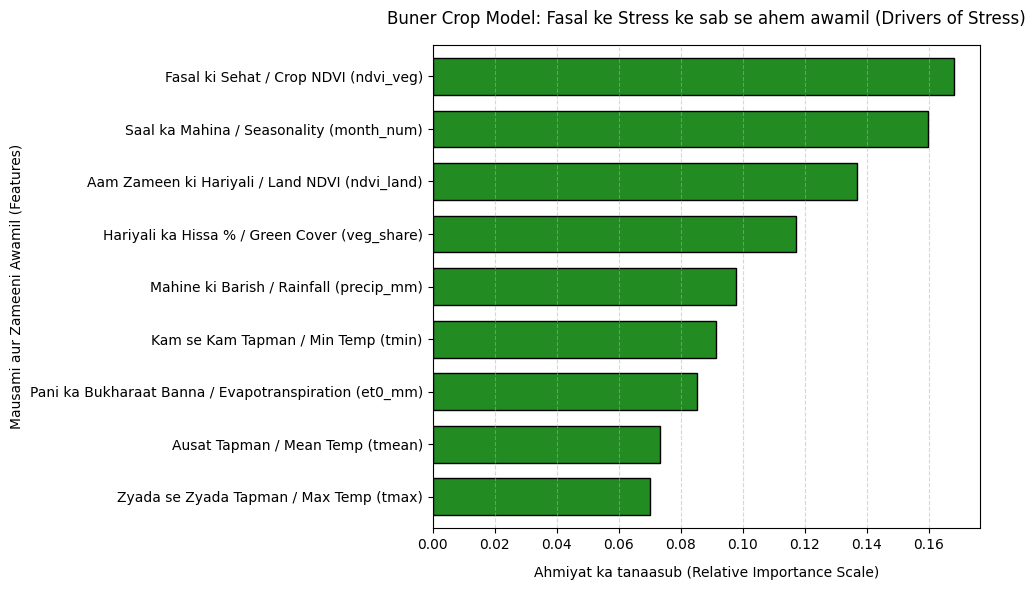

Sab se ahem 3 wajahen:
1. Fasal ki Sehat / Crop NDVI (ndvi_veg)
2. Saal ka Mahina / Seasonality (month_num)
3. Aam Zameen ki Hariyali / Land NDVI (ndvi_land)


In [17]:
import matplotlib.pyplot as plt

# Map technical feature names to clean Urdu/English descriptive labels
friendly_labels = {
    'ndvi_veg': 'Fasal ki Sehat / Crop NDVI (ndvi_veg)',
    'month_num': 'Saal ka Mahina / Seasonality (month_num)',
    'ndvi_land': 'Aam Zameen ki Hariyali / Land NDVI (ndvi_land)',
    'veg_share': 'Hariyali ka Hissa % / Green Cover (veg_share)',
    'precip_mm': 'Mahine ki Barish / Rainfall (precip_mm)',
    'tmin': 'Kam se Kam Tapman / Min Temp (tmin)',
    'et0_mm': 'Pani ka Bukharaat Banna / Evapotranspiration (et0_mm)',
    'tmean': 'Ausat Tapman / Mean Temp (tmean)',
    'tmax': 'Zyada se Zyada Tapman / Max Temp (tmax)'
}

# Prepare sorted importance values with mapped labels
imp = pd.Series(model.feature_importances_, index=feats)
imp = imp.rename(index=friendly_labels).sort_values()

# Generate descriptive plot
plt.figure(figsize=(10, 6))
imp.plot.barh(color='forestgreen', edgecolor='black', width=0.7)
plt.title('Buner Crop Model: Fasal ke Stress ke sab se ahem awamil (Drivers of Stress)', fontsize=12, pad=15)
plt.xlabel('Ahmiyat ka tanaasub (Relative Importance Scale)', fontsize=10, labelpad=10)
plt.ylabel('Mausami aur Zameeni Awamil (Features)', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('Sab se ahem 3 wajahen:')
for idx, val in enumerate(imp.sort_values(ascending=False).head(3).index, 1):
    print(f"{idx}. {val}")

In [16]:
# Live prediction — akhri mahine (Dec 2025) se agle mahine ka stress risk
last = df.iloc[[-1]]
risk = model.predict_proba(last[feats])[0]
print('Akhri mahina:', last['month'].iloc[0], '| NDVI:', last['ndvi_veg'].iloc[0])
print('Agle mahine stress ka risk:', round(float(risk[1]) * 100, 1), '%')
print('Matlab:', 'KHATRA kam hai ✅' if risk[1] < 0.5 else 'STRESS ka khatra hai ⚠️')


Akhri mahina: 2025-12 | NDVI: 0.298
Agle mahine stress ka risk: 19.0 %
Matlab: KHATRA kam hai ✅


In [20]:
import joblib
from google.colab import files

# Model ko .pkl file me save karein
model_filename = 'buner_crop_model.pkl'
joblib.dump(best_model, model_filename)
print(f"Model '{model_filename}' ke naam se save ho gaya hai! ✅")

# Browser me auto-download trigger karein
files.download(model_filename)

Model 'buner_crop_model.pkl' ke naam se save ho gaya hai! ✅


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🖥️ Custom Model Integration
Aapka trained Random Forest model (`buner_crop_model.pkl`) tayar hai. Aap is model ko locally ya kisi bhi custom integration script ke zariye load kar ke predictions hasil kar sakte hain.

In [22]:
# Custom Integration Template
import joblib
import pandas as pd

# Model load karne ka tariqa
model_filename = 'buner_crop_model.pkl'
loaded_model = joblib.load(model_filename)
print(f"Model '{model_filename}' successfully load ho gaya hai! Ready for custom usage.")

Model 'buner_crop_model.pkl' successfully load ho gaya hai! Ready for custom usage.


### 🚀 Custom Web App Deployment

In [19]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search over
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the base model
rf = RandomForestClassifier(random_state=42)

# Set up Grid Search (using TimeSeriesSplit or standard 3-fold since data is small)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(train[feats], train['stress_next'])

# Best model
best_model = grid_search.best_estimator_
opt_pred = best_model.predict(test[feats])
opt_accuracy = accuracy_score(test['stress_next'], opt_pred)

print("=== OPTIMIZATION RESULTS ===")
print("Behtareen Parameters (Best Params):", grid_search.best_params_)
print(f"Purani Accuracy: {round(accuracy_score(test['stress_next'], pred), 3)}")
print(f"Nayi Optimized Accuracy: {round(opt_accuracy, 3)}")
print("\nClassification Report (Optimized Model):")
print(classification_report(test['stress_next'], opt_pred, zero_division=0))

=== OPTIMIZATION RESULTS ===
Behtareen Parameters (Best Params): {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Purani Accuracy: 0.857
Nayi Optimized Accuracy: 0.857

Classification Report (Optimized Model):
              precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.67      1.00      0.80         2

    accuracy                           0.86         7
   macro avg       0.83      0.90      0.84         7
weighted avg       0.90      0.86      0.86         7



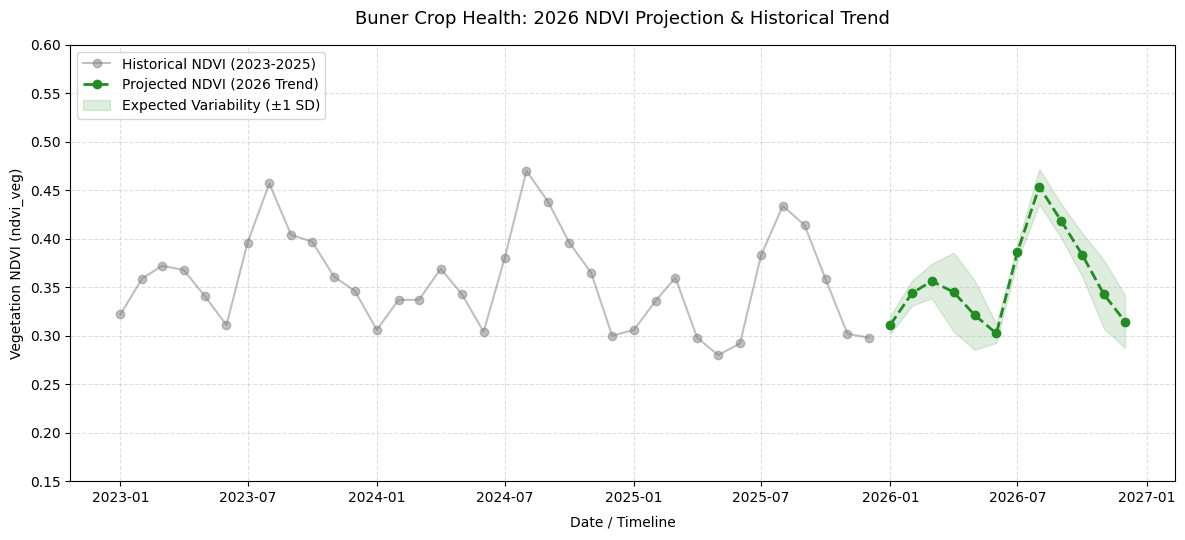

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Calculate historical monthly climatology (mean & standard deviation for each calendar month)
df['month_num'] = pd.to_datetime(df['month']).dt.month
monthly_stats = df.groupby('month_num')['ndvi_veg'].agg(['mean', 'std']).reset_index()

# Generate projection timelines for 2026
projection_months = [f'2026-{m:02d}' for m in range(1, 13)]
x_proj = pd.to_datetime(projection_months)

# Historical records for plotting
x_hist = pd.to_datetime(df['month'])
y_hist = df['ndvi_veg']

# Plotting
plt.figure(figsize=(12, 5.5))

# Plot historical actuals
plt.plot(x_hist, y_hist, 'o-', color='gray', alpha=0.5, label='Historical NDVI (2023-2025)')

# Plot projection line (2026)
plt.plot(x_proj, monthly_stats['mean'], 'o--', color='forestgreen', linewidth=2, label='Projected NDVI (2026 Trend)')

# Plot confidence interval (1 standard deviation representing seasonal variability)
plt.fill_between(x_proj,
                 monthly_stats['mean'] - monthly_stats['std'],
                 monthly_stats['mean'] + monthly_stats['std'],
                 color='forestgreen', alpha=0.15, label='Expected Variability (±1 SD)')

# Formatting
plt.title('Buner Crop Health: 2026 NDVI Projection & Historical Trend', fontsize=13, pad=15)
plt.xlabel('Date / Timeline', fontsize=10, labelpad=8)
plt.ylabel('Vegetation NDVI (ndvi_veg)', fontsize=10)
plt.ylim(0.15, 0.6)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper left', frameon=True, shadow=False)
plt.tight_layout()
plt.show()